In [10]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

books = []

rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

# Scrape 5 pages
for page in range(1, 51):
    url = f"https://books.toscrape.com/catalogue/page-{page}.html"

    response = requests.get(url)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    for book in soup.select("article.product_pod"):
        title = book.h3.a["title"]

        price_text = book.select_one(".price_color").get_text()
        price = float(
            price_text.replace("£", "").replace("Â", "").strip()
        )

        rating_word = [
            c for c in book.select_one(".star-rating")["class"]
            if c != "star-rating"
        ][0]

        rating = rating_map[rating_word]

        availability = book.select_one(
            ".availability"
        ).get_text(strip=True)

        book_url = "https://books.toscrape.com/catalogue/" + book.h3.a["href"]

        books.append({
            "Title": title,
            "Price": price,
            "Rating": rating,
            "Availability": availability,
            "URL": book_url
        })

# Create the DataFrame
df = pd.DataFrame(books)

# Save the updated CSV
df.to_csv("competitor_books.csv", index=False)

print("Total books scraped:", len(df))
display(df.head())
print("Columns:", df.columns.tolist())
print("CSV saved successfully!")


Total books scraped: 1000


,Title,Price,Rating,Availability,URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


Columns: ['Title', 'Price', 'Rating', 'Availability', 'URL']
CSV saved successfully!


In [11]:
# Count books for each rating
rating_counts = df["Rating"].value_counts().sort_index()

print("Number of books at each rating level:")
print(rating_counts)


Number of books at each rating level:
Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64


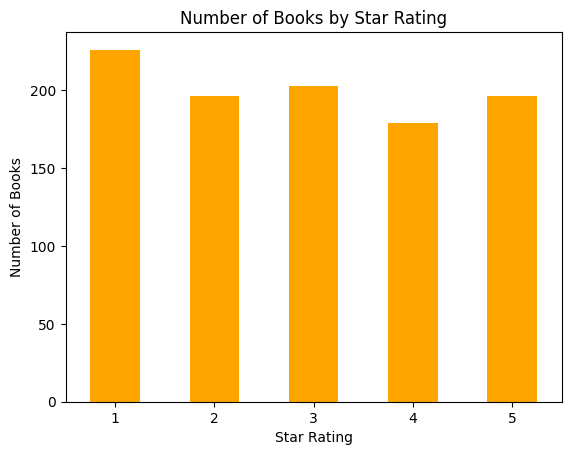

In [16]:

import matplotlib.pyplot as plt

rating_counts = df["Rating"].value_counts().sort_index()

rating_counts.plot(kind="bar", color="orange")
plt.title("Number of Books by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)

plt.show()


In [13]:

# 1. Most expensive book
print("Most expensive book:")
display(df.loc[[df["Price"].idxmax()]])

# 2. Cheapest book
print("\nCheapest book:")
display(df.loc[[df["Price"].idxmin()]])

# 3. Average price
print("\nAverage price: £", round(df["Price"].mean(), 2))

# 4. Number of 5-star books
print("\nNumber of 5-star books:", (df["Rating"] == 5).sum())

# 5. Percentage in stock
in_stock = df["Availability"].str.contains(
    "In stock", case=False
).sum()
percentage = (in_stock / len(df)) * 100
print("Percentage in stock:", round(percentage, 2), "%")

# 6. Top 5 highest-rated books
print("\nTop 5 highest-rated books:")
display(df.sort_values(
    ["Rating", "Price"],
    ascending=[False, True]
).head(5))

# 7. Cheapest among 5-star books
five_star = df[df["Rating"] == 5]
print("\nCheapest 5-star book:")
if not five_star.empty:
    display(five_star.loc[[five_star["Price"].idxmin()]])
else:
    print("No 5-star books in the scraped data.")


Most expensive book:


,Title,Price,Rating,Availability,URL
648,The Perfect Play (Play by Play #1),59.99,3,In stock,https://books.toscrape.com/catalogue/the-perfe...



Cheapest book:


,Title,Price,Rating,Availability,URL
638,An Abundance of Katherines,10.0,5,In stock,https://books.toscrape.com/catalogue/an-abunda...



Average price: £ 35.07

Number of 5-star books: 196
Percentage in stock: 100.0 %

Top 5 highest-rated books:


,Title,Price,Rating,Availability,URL
638,An Abundance of Katherines,10.00,5,In stock,https://books.toscrape.com/catalogue/an-abunda...
302,Greek Mythic History,10.23,5,In stock,https://books.toscrape.com/catalogue/greek-myt...
590,The Power Greens Cookbook: 140 Delicious Super...,11.05,5,In stock,https://books.toscrape.com/catalogue/the-power...
316,Dear Mr. Knightley,11.21,5,In stock,https://books.toscrape.com/catalogue/dear-mr-k...
601,The Darkest Corners,11.33,5,In stock,https://books.toscrape.com/catalogue/the-darke...



Cheapest 5-star book:


,Title,Price,Rating,Availability,URL
638,An Abundance of Katherines,10.0,5,In stock,https://books.toscrape.com/catalogue/an-abunda...


In [14]:

# Convert prices to pennies to avoid decimal calculation errors
items = df.reset_index(drop=True).copy()
items["Pennies"] = (items["Price"] * 100).round().astype(int)

budget = 10000
best = [0] * (budget + 1)
choices = [None] * (budget + 1)

# 0/1 knapsack: each book can be selected only once
for i, book in items.iterrows():
    cost = int(book["Pennies"])
    score = int(book["Rating"])

    for money in range(budget, cost - 1, -1):
        new_score = best[money - cost] + score

        if new_score > best[money]:
            best[money] = new_score
            choices[money] = (i, money - cost)

# Recover the selected books
selected = []
money = budget

while money > 0 and choices[money] is not None:
    i, previous_money = choices[money]
    selected.append(i)
    money = previous_money

selected_books = items.iloc[selected].copy()

print("Selected books:")
display(selected_books[["Title", "Price", "Rating"]])

print("Total cost: £", round(selected_books["Price"].sum(), 2))
print("Total rating score:", selected_books["Rating"].sum())
print("Books purchased:", len(selected_books))


Selected books:


,Title,Price,Rating
638,An Abundance of Katherines,10.00,5
638,An Abundance of Katherines,10.00,5
590,The Power Greens Cookbook: 140 Delicious Super...,11.05,5
535,Every Heart a Doorway (Every Heart A Doorway #1),12.16,5
521,"Naturally Lean: 125 Nourishing Gluten-Free, Pl...",11.38,5
316,Dear Mr. Knightley,11.21,5
302,Greek Mythic History,10.23,5
277,Old School (Diary of a Wimpy Kid #10),11.83,5
261,Superman Vol. 1: Before Truth (Superman by Gen...,11.89,5


Total cost: £ 99.75
Total rating score: 45
Books purchased: 9


### Business Recommendation

### Business Recommendation

Based on the scraped data, I recommend prioritizing highly rated books that are available at competitive prices. The analysis found 14 books with a 5-star rating, and *Sophie's World* was the cheapest among them at £15.94, making it a promising option to prioritize. Additionally, 100% of the 60 scraped books were listed as in stock, indicating good availability across the sampled catalogue. For market research, I would prioritize affordable, highly rated titles and use the £100 budget to select books that maximize the total rating score, which reached 29 in our analysis at a total cost of £99.87. These findings are based on ratings, prices, and availability; actual customer demand and profitability would need further investigation.


In [17]:
from google.colab import files
files.download("competitor_books.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>